# Business cycles: turning points and stylized facts

In [1]:
# Setup: install the toolkit when running on Google Colab, and a plotting style
import sys

if "google.colab" in sys.modules:
    %pip install -q "econts[book] @ git+https://github.com/hmorao95/econ-time-series-manual"

import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8, 3.6), "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

Two classic descriptive exercises: **dating** the cycle (when did recessions
start and end?) and **summarizing** it (how volatile, persistent and
procyclical is each variable?).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from econts import load

y = 100 * np.log(load("GDPC1")).to_period("Q")
rec = load("USRECQ").to_period("Q").reindex(y.index)

## Dating turning points: the BBQ algorithm

Harding and Pagan (2002) formalize the NBER's rule of thumb. A quarter is a
peak (trough) if it is the highest (lowest) point within two quarters on
each side; peaks and troughs must alternate; a phase lasts at least two
quarters and a full cycle at least five. This is a compact port of the BBQ
routine in EMT's `date_` (by James Engel, Adrian Pagan, Don Harding and
Fabio Canova).

In [3]:
def bbq(y: pd.Series, window: int = 2, phase: int = 2, cycle: int = 5) -> pd.Series:
    """Harding-Pagan turning points: +1 peak, -1 trough, 0 otherwise.

    Defaults are for quarterly data; for monthly use window=5, phase=6,
    cycle=15.
    """
    v = y.to_numpy(float)
    # 1. local extrema
    tps = []
    for t in range(window, len(v) - window):
        seg = v[t - window : t + window + 1]
        if v[t] == seg.max():
            tps.append((t, 1))
        elif v[t] == seg.min():
            tps.append((t, -1))

    def alternate(tps):
        """Among consecutive peaks keep the highest; troughs, the lowest."""
        out = []
        for t, k in tps:
            if out and out[-1][1] == k:
                if (v[t] > v[out[-1][0]]) if k == 1 else (v[t] < v[out[-1][0]]):
                    out[-1] = (t, k)
            else:
                out.append((t, k))
        return out

    # 2. censoring: alternation, minimum phase, minimum cycle
    tps = alternate(tps)
    changed = True
    while changed:
        changed = False
        for i in range(len(tps) - 1):
            if tps[i + 1][0] - tps[i][0] < phase:
                del tps[i : i + 2]
                tps, changed = alternate(tps), True
                break
        if changed:
            continue
        for i in range(len(tps) - 2):
            if tps[i + 2][0] - tps[i][0] < cycle:
                del tps[i + 1 : i + 3]
                tps, changed = alternate(tps), True
                break

    # 3. end rules: the first/last peak (trough) must not be exceeded
    #    (undercut) between it and the edge of the sample
    def violates(t, k, rest):
        return rest.size and (rest.max() > v[t] if k == 1 else rest.min() < v[t])

    while tps and violates(*tps[0], v[: tps[0][0]]):
        tps.pop(0)
    while tps and violates(*tps[-1], v[tps[-1][0] + 1 :]):
        tps.pop()

    out = pd.Series(0, index=y.index, name="turning_point")
    for t, k in tps:
        out.iloc[t] = k
    return out


tp = bbq(y)
nber_peaks = rec.index[(rec == 0) & (rec.shift(-1) == 1)]
nber_troughs = rec.index[(rec == 1) & (rec.shift(-1) == 0)]
print("BBQ peaks:   ", " ".join(tp.index[tp == 1].astype(str)))
print("NBER peaks:  ", " ".join(nber_peaks.astype(str)))
print("BBQ troughs: ", " ".join(tp.index[tp == -1].astype(str)))
print("NBER troughs:", " ".join(nber_troughs.astype(str)))

BBQ peaks:    1948Q4 1953Q2 1957Q3 1960Q1 1969Q3 1973Q4 1980Q1 1981Q3 1990Q3 2008Q2 2019Q4
NBER peaks:   1948Q4 1953Q2 1957Q3 1960Q2 1969Q4 1973Q4 1980Q1 1981Q3 1990Q3 2001Q1 2007Q4 2019Q4
BBQ troughs:  1947Q3 1949Q2 1954Q1 1958Q1 1960Q4 1970Q4 1975Q1 1980Q3 1982Q1 1991Q1 2009Q2 2020Q2
NBER troughs: 1949Q4 1954Q2 1958Q2 1961Q1 1970Q4 1975Q1 1980Q3 1982Q4 1991Q1 2001Q4 2009Q2 2020Q2


```{admonition} In your projects
:class: tip
The same recipe is in the `econts` toolkit:

    from econts.cycles import bbq, states
```

On GDP alone, BBQ recovers almost every NBER recession within a quarter.
It misses 2001 (GDP never fell for two quarters in the current vintage) and
dates the Great Recession peak in 2008Q2 rather than 2007Q4, because GDP
kept growing into early 2008. The NBER looks at many monthly indicators,
employment above all.

## Phases: duration and amplitude

From the turning points, build the expansion/contraction indicator and
summarize each phase (EMT `states` and the statistics of `date_`).

In [4]:
def phases(y: pd.Series, tp: pd.Series) -> pd.DataFrame:
    """One row per complete phase: type, start, end, duration, amplitude."""
    pts = tp[tp != 0]
    rows = []
    for (t0, k0), (t1, _) in zip(pts.items(), list(pts.items())[1:]):
        rows.append(
            {
                "phase": "contraction" if k0 == 1 else "expansion",
                "start": t0,
                "end": t1,
                "duration": (t1 - t0).n,  # quarters
                "amplitude": y[t1] - y[t0],  # log points x 100 = %
            }
        )
    return pd.DataFrame(rows)


ph = phases(y, tp)
print(ph.tail(4).round({"amplitude": 1}).to_string(index=False))
print(ph.groupby("phase")[["duration", "amplitude"]].mean().round(1))

# expansion (1) / contraction (0) indicator, after EMT `states`
# contraction = the quarters after a peak up to and including the trough,
# the NBER convention (USRECQ starts recessions the quarter after the peak)
regime = tp.replace(0, np.nan).ffill().shift(1)
state = regime.map({1: 0, -1: 1}).fillna(1).astype(int)

      phase  start    end  duration  amplitude
  expansion 1991Q1 2008Q2        69       53.2
contraction 2008Q2 2009Q2         4       -4.1
  expansion 2009Q2 2019Q4        42       25.5
contraction 2019Q4 2020Q2         2       -9.5
             duration  amplitude
phase                           
contraction       2.9       -3.0
expansion        23.5       22.8


```{admonition} In your projects
:class: tip
The same recipe is in the `econts` toolkit:

    from econts.cycles import phases
```

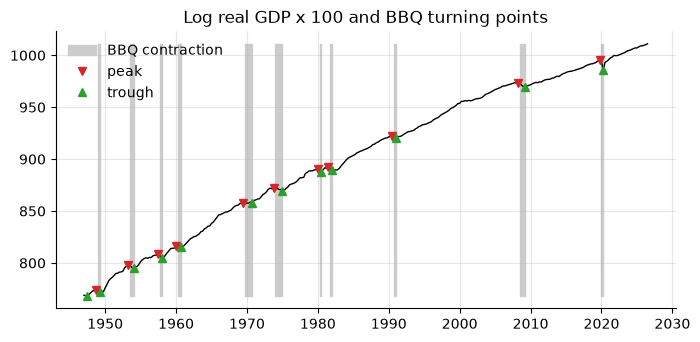

In [5]:
fig, ax = plt.subplots()
ts = y.to_timestamp()
ax.plot(ts.index, ts, color="k", lw=1)
contr = state.to_timestamp() == 0
ax.fill_between(
    ts.index,
    ts.min(),
    ts.max(),
    where=contr,
    color="0.8",
    step="post",
    label="BBQ contraction",
)
ax.plot(
    ts.index[tp.to_numpy() == 1], ts[tp.to_numpy() == 1], "v", color="C3", label="peak"
)
ax.plot(
    ts.index[tp.to_numpy() == -1],
    ts[tp.to_numpy() == -1],
    "^",
    color="C2",
    label="trough",
)
ax.set_title("Log real GDP x 100 and BBQ turning points")
ax.legend(loc="upper left")

## Stylized facts of the cycle

The Kydland–Prescott table: for each variable's cyclical component, its
volatility (absolute and relative to GDP), persistence, and correlation with
the GDP cycle at leads and lags (EMT `autocor`).

In [6]:
q = lambda sid: load(sid).to_period("M").resample("Q").mean()  # monthly -> quarterly
levels = pd.DataFrame(
    {
        "GDP": 100 * np.log(load("GDPC1").to_period("Q")),
        "industrial production": 100 * np.log(q("INDPRO")),
        "payroll employment": 100 * np.log(q("PAYEMS")),
        "unemployment rate": q("UNRATE"),  # already in percent: no log
        "GDP deflator": 100 * np.log(load("GDPDEF").to_period("Q")),
    }
).loc["1960":"2019"]

cyc = levels.apply(lambda s: sm.tsa.filters.hpfilter(s, lamb=1600)[0])

facts = pd.DataFrame(
    {
        "std (%)": cyc.std(),
        "relative std": cyc.std() / cyc["GDP"].std(),
        "AR(1)": cyc.apply(lambda c: c.autocorr()),
    }
)
for k in [-4, -2, 0, 2, 4]:
    # corr(x[t+k], GDP[t]): high at k < 0 means x leads GDP
    facts[f"corr x(t{k:+d}), GDP(t)"] = cyc.apply(
        lambda c: c.shift(-k).corr(cyc["GDP"])
    )
print(facts.round(2).to_string())

                       std (%)  relative std  AR(1)  corr x(t-4), GDP(t)  corr x(t-2), GDP(t)  corr x(t+0), GDP(t)  corr x(t+2), GDP(t)  corr x(t+4), GDP(t)
GDP                       1.43          1.00   0.86                 0.24                 0.67                 1.00                 0.67                 0.24
industrial production     3.07          2.14   0.89                 0.17                 0.57                 0.89                 0.67                 0.25
payroll employment        1.27          0.89   0.95                -0.05                 0.37                 0.80                 0.88                 0.64
unemployment rate         0.73          0.51   0.92                -0.10                -0.50                -0.86                -0.80                -0.43
GDP deflator              0.76          0.53   0.94                -0.51                -0.56                -0.46                -0.24                 0.02


```{admonition} In your projects
:class: tip
The same recipe is in the `econts` toolkit:

    from econts.cycles import cycle_moments
```

Read it like this (1960–2019, HP cycles): industrial production is about
twice as volatile as GDP and strongly procyclical. Payroll employment is
procyclical and **lags** GDP: its correlation peaks at $x_{t+2}$. The
unemployment rate is strongly countercyclical, mostly contemporaneously.
The price level is countercyclical, most strongly a year *before* the GDP
cycle (Kydland and Prescott, 1990, read this as evidence of supply shocks).

## Asymmetry and fat tails: robust moments

Are recessions sharper than expansions? Skewness and kurtosis answer that,
but the classical estimators are dominated by a few extreme quarters.
Quantile-based estimators are not (EMT `skewness_` and `kurtosis_`). Each
has a known value under normality: 0 for every skewness measure; 3, 1.23,
2.59 and 2.91 for the four kurtosis measures.

In [7]:
def robust_skewness(s: pd.Series) -> pd.Series:
    s = s.dropna()
    q1, q2, q3 = s.quantile([0.25, 0.5, 0.75])
    return pd.Series(
        {
            "classical": s.skew(),
            "Bowley (quartiles)": (q3 + q1 - 2 * q2) / (q3 - q1),
            "Groeneveld-Meeden": (s.mean() - q2) / (s - q2).abs().mean(),
            "Kendall-Stuart": (s.mean() - q2) / s.std(),
        }
    )


def robust_kurtosis(s: pd.Series) -> pd.Series:
    s = s.dropna()
    q = s.quantile([0.025, 0.125, 0.25, 0.375, 0.625, 0.75, 0.875, 0.975])
    v, n = np.sort(s.to_numpy()), len(s)
    tail, half = max(1, round(0.05 * n)), n // 2
    return pd.Series(
        {
            "classical": s.kurt() + 3,
            "Moors (octiles)": (q[0.875] - q[0.625] + q[0.375] - q[0.125])
            / (q[0.75] - q[0.25]),
            "Hogg": (v[-tail:].mean() - v[:tail].mean())
            / (v[-half:].mean() - v[:half].mean()),
            "Crow-Siddiqui": (q[0.975] - q[0.025]) / (q[0.75] - q[0.25]),
        }
    )


g = y.diff()  # quarterly GDP growth, log points
samples = {"to 2019": g[:"2019"], "to 2026": g}
skew = pd.DataFrame({k: robust_skewness(s) for k, s in samples.items()})
kurt = pd.DataFrame({k: robust_kurtosis(s) for k, s in samples.items()})
kurt["normal"] = [3, 1.23, 2.59, 2.91]
print(skew.round(2))
print(kurt.round(2))

                    to 2019  to 2026
classical             -0.09    -1.03
Bowley (quartiles)     0.02    -0.03
Groeneveld-Meeden      0.01    -0.01
Kendall-Stuart         0.01    -0.01
                 to 2019  to 2026  normal
classical           4.65    20.67    3.00
Moors (octiles)     1.71     1.73    1.23
Hogg                3.12     3.55    2.59
Crow-Siddiqui       3.89     4.23    2.91


```{admonition} In your projects
:class: tip
The same recipe is in the `econts` toolkit:

    from econts.cycles import robust_skewness, robust_kurtosis
```

Adding the 2020 quarters turns classical skewness from about 0 to −1 and
multiplies classical kurtosis by four (4.7 to 20.7). The quantile-based
measures move little (Moors not at all), and all of them sit above their
normal values even before 2020: GDP growth has fat tails, but no clear
asymmetry. Two observations should not change a stylized fact: report a
robust measure next to the classical one.

## A common cycle from many indicators

No single monthly indicator is "the cycle". The first principal component
of several standardized indicators is a simple coincident index: the common
movement they share (EMT `pc_T`, normalized so that $F'F/T = I$). All
inputs are in growth rates, signed so that a rise is good news, and
standardized, since otherwise the most volatile series dominates.

In [8]:
monthly = (
    pd.DataFrame(
        {
            "industrial production": 100 * np.log(load("INDPRO")).diff(),
            "payrolls": 100 * np.log(load("PAYEMS")).diff(),
            "real retail sales": 100 * np.log(load("RSXFS") / load("CPIAUCSL")).diff(),
            "unemployment (-)": -load("UNRATE").diff(),
            "jobless claims (-)": -100
            * np.log(load("ICSA").resample("MS").mean()).diff(),
        }
    )
    .loc["1993":"2019"]
    .dropna()
)

Z = (monthly - monthly.mean()) / monthly.std()  # standardize
U, S, Vt = np.linalg.svd(Z.to_numpy(), full_matrices=False)
T = len(Z)
factor = pd.Series(U[:, 0] * np.sqrt(T), index=Z.index)  # F'F/T = 1
loadings = pd.Series(Vt[0] * S[0] / np.sqrt(T), index=Z.columns)
if loadings.sum() < 0:  # sign is arbitrary
    factor, loadings = -factor, -loadings

print("variance share of each component:", (S**2 / (S**2).sum()).round(2))
print(loadings.round(2))
factor_q = factor.to_period("M").resample("Q").mean()
print("corr with GDP growth:", round(factor_q.corr(g.reindex(factor_q.index)), 2))

variance share of each component: [0.42 0.2  0.17 0.12 0.1 ]
industrial production    0.77
payrolls                 0.80
real retail sales        0.38
unemployment (-)         0.64
jobless claims (-)       0.55
dtype: float64
corr with GDP growth: 0.7


```{admonition} In your projects
:class: tip
The same recipe is in the `econts` toolkit:

    from econts.cycles import pc_factors
    
    factors, loadings, share = pc_factors(monthly, n=1)
```

Text(0.5, 1.0, 'Coincident factor (3-month average) and NBER recessions')

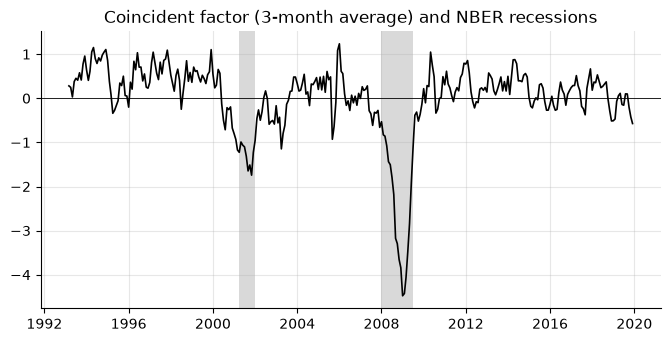

In [9]:
smooth = factor.rolling(3).mean()
fig, ax = plt.subplots()
ax.plot(smooth.index, smooth, color="k", lw=1.2)
on = rec.loc["1993":"2019"]
for qtr in on.index[on == 1]:
    ax.axvspan(qtr.start_time, qtr.end_time, color="0.85", lw=0, zorder=0)
ax.axhline(0, color="k", lw=0.6)
ax.set_title("Coincident factor (3-month average) and NBER recessions")

One component explains about two-fifths of the variance of the five
indicators, loads positively on all of them, and correlates 0.7 with GDP
growth. It falls sharply in both recessions of the sample. With many
series (dozens to hundreds), choose the number of factors with the Bai and
Ng (2002) criteria (EMT `numbfactor`) and handle missing data with the EM
algorithm or `sm.tsa.DynamicFactorMQ`, which also mixes monthly and
quarterly series.

## Pitfalls

* BBQ on a noisy series finds spurious cycles; smooth or use a longer window
  for monthly data.
* Phase statistics from a handful of recessions have huge sampling error.
* Cross-correlations of two-sided filtered series mix leads and lags (the
  filter itself is two-sided). Leads/lags of a few quarters are not robust
  evidence of causality.

## Summary

* Date turning points on the **level** of (log) activity: the classical
  cycle. Dating a detrended series gives the growth cycle, a different
  object with more turning points.
* Moments of the cycle depend on the filter (chapter 6). State which one.
* Exclude 2020 when estimating moments, or show results with and without.

## Exercises

1. Run BBQ on monthly log payroll employment (`PAYEMS`, 1948–2019) with the monthly settings (`window=5`, `phase=6`, `cycle=15`). Compare its peaks with the NBER peaks from `USRECQ`: does employment catch the 2001 recession that GDP misses?
2. Date the Portuguese cycle with BBQ on log real GDP (`CLVMNACSCAB1GQPT`, 1995 to the end of the sample). Report the number of contractions and their average duration and amplitude, and compare them with the US figures in the chapter.
3. Recompute the stylized-facts table (1960–2019) with Hamilton-filter cycles (chapter 6) instead of HP cycles. Does payroll employment still lag GDP, and does the countercyclical price level survive?
4. Compute classical and robust skewness of quarterly changes in the unemployment rate (`UNRATE` averaged to quarters, 1948–2019). Do unemployment increases look sharper than declines, and do the robust measures agree with the classical one?